# 06 · Decision framework: which index, which knob, and how to know

**The question.** You have vectors and a latency budget. Do you need an index at all — and if
so, which one, set how?

**The claim.** Below a few hundred thousand vectors, exact search in numpy or faiss is genuinely
fine; do not over-engineer. Above that, pick the index by the corner of the triangle you can
afford to lose — memory, build time, or recall — and then *measure* recall against brute force on
a sample, because an index you have not recall-tested returns results of unknown quality.

**By the end** you will have the decision table, the knob-to-corner map, a measured answer to
"when does an index pay for itself?", and a ten-line recall test you can run against any index
or vector database.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import visualisation as vis
from src.artifacts import save_figure, save_json
from src.config import get_settings
from src.datasets.vectors import load_dataset
from src.evaluation.speed import machine_info, pinned_threads

S = get_settings()
K, SEED, THREADS = S.eval.k, S.seed, S.bench.threads
NB_START = time.perf_counter()
MACHINE = machine_info(THREADS)
pd.set_option("display.width", 140, "display.max_colwidth", 90)


def show(fig, slug: str) -> None:
    """Save the figure as outputs/figures/<slug>.png, then display it once."""
    save_figure(fig, slug)
    plt.close(fig)
    display(fig)


print(MACHINE)

{'cpu': 'Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz', 'logical_cpus': 2, 'threads': 1, 'python': '3.14.2', 'numpy': '2.5.4', 'faiss': '1.15.1', 'hnswlib': '0.8.0'}


## When does an index pay for itself?

Exact search is a straight line in N (notebook 01). An index adds a build step and buys a flatter
line. On prefixes of the 200,000-vector clustered set, each method is tuned to the *cheapest*
setting that still reaches recall@10 ≥ 0.95 at that size — `nprobe` for IVF (with
`nlist ≈ √N`, rounded to a power of two), `ef_search` for HNSW — and then timed one query at a
time on one thread.

In [2]:
from src.datasets.vectors import exact_ground_truth
from src.evaluation.recall import recall_at_k
from src.evaluation.speed import median_latency_ms, timed_build
from src.reference.compare import FaissFlat, FaissIVF, HnswlibHNSW

dec, h, bench = S.decision, S.hnsw, S.bench
clustered = load_dataset("clustered")
q = clustered.queries[: bench.max_queries]
rows = []

def tune(index, knob, candidates, gt):
    # smallest knob value reaching the target; the largest if none does
    for value in candidates:
        setattr(index, knob, value)
        _, ids = index.search(q, K)
        rec = recall_at_k(ids, gt, K)
        if rec >= dec.target_recall:
            return value, rec
    return value, rec

with pinned_threads(THREADS):
    for n in dec.sizes:
        xb = clustered.base[:n]
        gt, _ = exact_ground_truth(xb, q, K)
        flat = FaissFlat()
        build = timed_build(flat, xb)
        rows.append({"n": n, "method": "exact (faiss Flat)", "knob": "-", "recall": 1.0, "build_s": build,
                     "latency_ms": median_latency_ms(flat, q, K, warmup=bench.warmup)})
        nlist = int(2 ** round(np.log2(np.sqrt(n))))  # ~sqrt(N): enough training points per list
        ivf = FaissIVF(nlist=nlist, seed=SEED)
        build = timed_build(ivf, xb)
        value, rec = tune(ivf, "nprobe", [p for p in dec.nprobe_candidates if p <= nlist], gt)
        rows.append({"n": n, "method": "IVF (faiss)", "knob": f"nlist={nlist}, nprobe={value}", "recall": rec,
                     "build_s": build, "latency_ms": median_latency_ms(ivf, q, K, warmup=bench.warmup)})
        hn = HnswlibHNSW(m=h.m, ef_construction=h.ef_construction, seed=SEED, threads=THREADS)
        build = timed_build(hn, xb)
        value, rec = tune(hn, "ef_search", dec.ef_candidates, gt)
        rows.append({"n": n, "method": "HNSW (hnswlib)", "knob": f"m={h.m}, ef={value}", "recall": rec,
                     "build_s": build, "latency_ms": median_latency_ms(hn, q, K, warmup=bench.warmup)})
        del flat, ivf, hn
pays = pd.DataFrame(rows)
display(pays.pivot(index="n", columns="method", values="latency_ms").round(3))

method,HNSW (hnswlib),IVF (faiss),exact (faiss Flat)
n,,,
12500,0.017,0.018,0.28
25000,0.018,0.028,0.43
50000,0.025,0.032,1.10
100000,0.033,0.049,3.71
200000,0.056,0.125,9.82


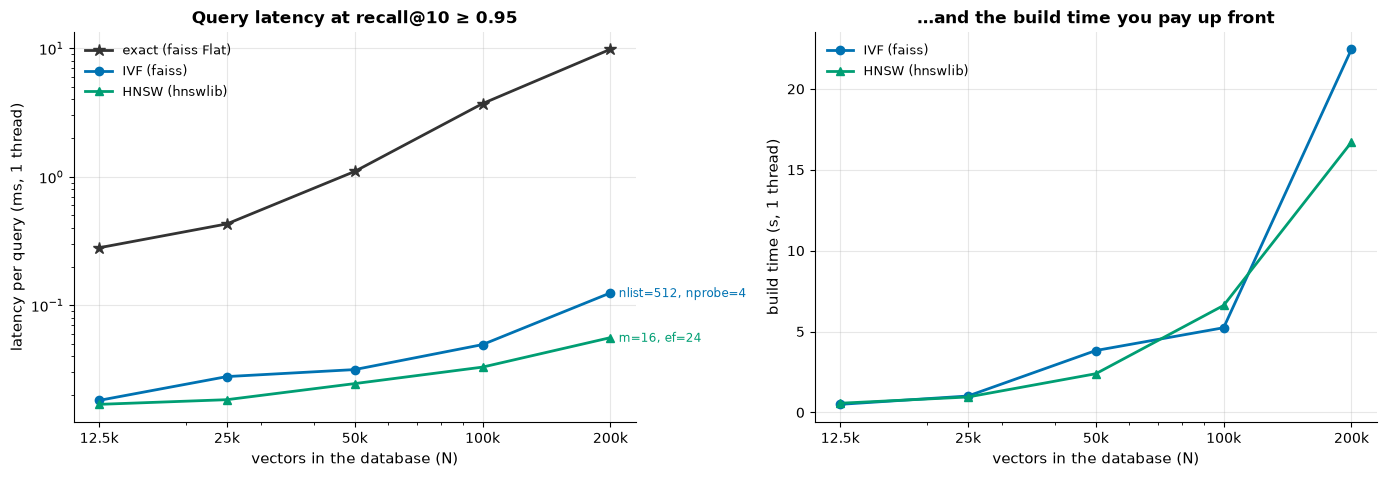

,n,method,knob,recall,build_s,latency_ms
0,12500,exact (faiss Flat),-,1.000,0.004,0.280
1,12500,IVF (faiss),"nlist=128, nprobe=1",0.986,0.500,0.018
2,12500,HNSW (hnswlib),"m=16, ef=16",0.997,0.569,0.017
3,25000,exact (faiss Flat),-,1.000,0.003,0.430
4,25000,IVF (faiss),"nlist=128, nprobe=1",0.964,1.017,0.028
5,25000,HNSW (hnswlib),"m=16, ef=16",0.986,0.955,0.018
6,50000,exact (faiss Flat),-,1.000,0.006,1.100
7,50000,IVF (faiss),"nlist=256, nprobe=2",0.989,3.827,0.032
8,50000,HNSW (hnswlib),"m=16, ef=16",0.984,2.393,0.025
9,100000,exact (faiss Flat),-,1.000,0.009,3.710


In [3]:
fig = vis.plot_when_index_pays(pays, dec.target_recall, 500_000)
show(fig, "06_when_an_index_pays")
save_json("06_when_an_index_pays", {"dataset": "clustered", "d": clustered.d, "k": K, "target_recall": dec.target_recall,
                                    "queries_timed": int(q.shape[0]), "machine": MACHINE, "rows": pays})
display(pays.round(3))

Exact search's latency climbs with N while the tuned indexes stay nearly flat — but notice the
absolute numbers. At the smaller sizes exact search answers in well under a millisecond or a few
milliseconds: if that fits your budget, the index buys you nothing but a build step, extra
memory and a recall you now have to monitor. That is `retrieval_arena`'s conclusion (numpy
brute force is fine below roughly 500,000 vectors) seen from the other side. The index earns
its keep when the straight line crosses your latency budget — or when you need many queries per
second from few cores.

## The decision table

In [4]:
from src.artifacts import load_json

best = pd.DataFrame(load_json("05_cheapest_at_recall_0.9")["wallclock_compiled"]).set_index("index")
pq_mem = load_json("03_summary")
hn_mem = load_json("04_summary")
decision = pd.DataFrame([
    {"situation": "under a few hundred thousand vectors, latency budget met",
     "choose": "exact search (numpy / faiss Flat)",
     "why": "always right, nothing to tune or monitor, no build step",
     "evidence": "notebook 01: linear in N; retrieval_arena: fine below ~500K"},
    {"situation": "best recall per millisecond; memory available",
     "choose": "HNSW",
     "why": "graph walk scores a tiny, shrinking share of the database",
     "evidence": f"notebook 05: {best.loc['hnsw', 'speed']:.0f}x exact at recall ≥ 0.9, "
                 f"{best.loc['hnsw', 'bytes_per_vector']:.0f} B/vector"},
    {"situation": "memory or build time matter more than the last bit of speed",
     "choose": "IVF",
     "why": "k-means trains in seconds; costs an id per vector (8 B) plus the centroids over the raw floats",
     "evidence": f"notebook 05: {best.loc['ivf', 'speed']:.0f}x exact at recall ≥ 0.9, "
                 f"{best.loc['ivf', 'bytes_per_vector']:.0f} B/vector"},
    {"situation": "memory is the hard limit",
     "choose": "PQ / IVFPQ (optionally re-rank the shortlist)",
     "why": "tens of times smaller; distances from codes",
     "evidence": f"notebook 03: {pq_mem['pq48_compression']:.0f}x smaller at recall {pq_mem['pq48_recall']:.2f}"},
    {"situation": "streaming inserts, no training, set or near-duplicate similarity",
     "choose": "LSH",
     "why": "no training, trivial inserts; dominated on dense embeddings",
     "evidence": "notebook 05: needs far more work for the same recall; hashing_101 for sets"},
])
save_json("06_decision_table", decision)
display(decision)

,situation,choose,why,evidence
0,"under a few hundred thousand vectors, latency budget met",exact search (numpy / faiss Flat),"always right, nothing to tune or monitor, no build step",notebook 01: linear in N; retrieval_arena: fine below ~500K
1,best recall per millisecond; memory available,HNSW,"graph walk scores a tiny, shrinking share of the database","notebook 05: 43x exact at recall ≥ 0.9, 1621 B/vector"
2,memory or build time matter more than the last bit of speed,IVF,k-means trains in seconds; costs an id per vector (8 B) plus the centroids over the ra...,"notebook 05: 6x exact at recall ≥ 0.9, 1552 B/vector"
3,memory is the hard limit,PQ / IVFPQ (optionally re-rank the shortlist),tens of times smaller; distances from codes,notebook 03: 27x smaller at recall 0.68
4,"streaming inserts, no training, set or near-duplicate similarity",LSH,"no training, trivial inserts; dominated on dense embeddings",notebook 05: needs far more work for the same recall; hashing_101 for sets


## Which knob moves which corner

In [5]:
knobs = pd.DataFrame([
    {"index": "IVF", "knob": "nprobe ↑ (search time)", "recall": "↑", "speed": "↓", "memory": "–", "build": "–"},
    {"index": "IVF", "knob": "nlist ↑ (build time)", "recall": "↓ at fixed nprobe", "speed": "↑", "memory": "≈", "build": "↑"},
    {"index": "PQ", "knob": "n_subvectors ↑ (bytes/vector)", "recall": "↑", "speed": "↓ (more lookups)", "memory": "↑", "build": "↑"},
    {"index": "HNSW", "knob": "ef_search ↑ (search time)", "recall": "↑", "speed": "↓", "memory": "–", "build": "–"},
    {"index": "HNSW", "knob": "m ↑ (build time)", "recall": "↑", "speed": "↓ per hop, ↑ fewer hops", "memory": "↑", "build": "↑"},
    {"index": "HNSW", "knob": "ef_construction ↑ (build time)", "recall": "↑", "speed": "–", "memory": "–", "build": "↑"},
    {"index": "LSH", "knob": "bands ↑", "recall": "↑", "speed": "↓", "memory": "↑", "build": "↑"},
])
save_json("06_knob_to_corner", knobs)
display(knobs)

,index,knob,recall,speed,memory,build
0,IVF,nprobe ↑ (search time),↑,↓,–,–
1,IVF,nlist ↑ (build time),↓ at fixed nprobe,↑,≈,↑
2,PQ,n_subvectors ↑ (bytes/vector),↑,↓ (more lookups),↑,↑
3,HNSW,ef_search ↑ (search time),↑,↓,–,–
4,HNSW,m ↑ (build time),↑,"↓ per hop, ↑ fewer hops",↑,↑
5,HNSW,ef_construction ↑ (build time),↑,–,–,↑
6,LSH,bands ↑,↑,↓,↑,↑


## Always recall-test against exact search

An approximate index never tells you what it missed. The only way to know its recall is to run
brute force on a sample of queries and compare — which is cheap, because you only need a few
hundred queries. `src/evaluation/recall.py` ships the function:

```python
from src.evaluation.recall import recall_on_sample
est = recall_on_sample(index, xb, queries, k=10, n_sample=200)   # any Index: scratch, faiss, hnswlib
print(f"recall@10 = {est.mean:.3f}  (95% CI {est.ci_low:.3f}–{est.ci_high:.3f})")
```

How many queries is enough? Take an IVF index on the news vectors at `nprobe = 4` (recall in
the 0.7s, with plenty of query-to-query variation), measure its per-query recall on all 1,000
held-out queries, and look at what samples of different sizes would have estimated:

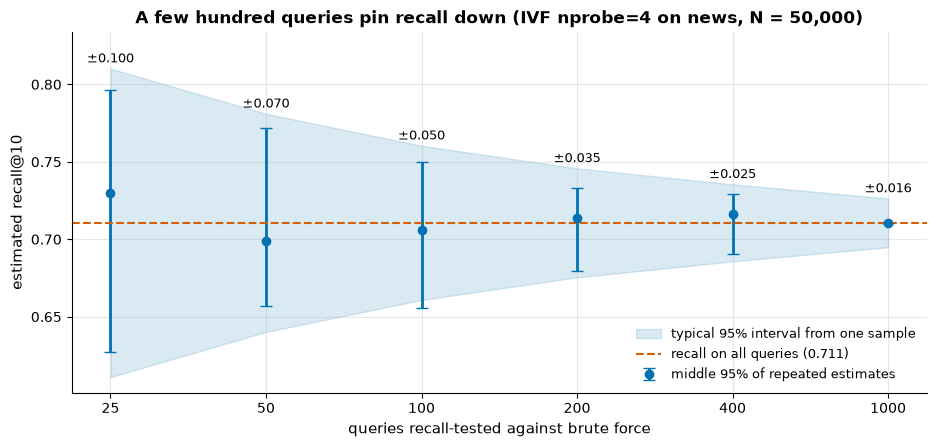

recall_on_sample with 200 queries: 0.709 (95% CI 0.673–0.745); all 1,000 queries: 0.711


In [6]:
from src.evaluation.recall import per_query_recall, recall_on_sample
from src.indexes.ivf import IVFIndex

news = load_dataset("news")
ivf = IVFIndex(nlist=S.ivf.nlist, seed=SEED)
ivf.train(news.base)
ivf.add(news.base)
ivf.nprobe = 4
_, ids = ivf.search(news.queries, K)
per_q = per_query_recall(ids, news.gt_ids, K)
true_recall = float(per_q.mean())
rng = np.random.default_rng(SEED)
size_rows = []
for n_s in dec.sample_sizes:
    est = np.array([rng.choice(per_q, size=n_s, replace=False).mean() for _ in range(dec.sample_repeats)])
    half = 1.96 * per_q.std(ddof=1) / np.sqrt(n_s)
    size_rows.append({"n_sample": n_s, "median": float(np.median(est)), "p2_5": float(np.percentile(est, 2.5)),
                      "p97_5": float(np.percentile(est, 97.5)), "ci_low": true_recall - half, "ci_high": true_recall + half})
sizes = pd.DataFrame(size_rows)
fig = vis.plot_recall_sample_size(sizes, true_recall, f"IVF nprobe=4 on news, N = {news.n:,}")
show(fig, "06_recall_sample_size")

demo = recall_on_sample(ivf, news.base, news.queries, k=K, n_sample=200, seed=SEED)
save_json("06_recall_sample_size", {"index": "ivf", "nlist": S.ivf.nlist, "nprobe": 4, "true_recall": true_recall,
                                    "repeats": dec.sample_repeats, "rows": sizes, "recall_on_sample_200": demo})
print(f"recall_on_sample with 200 queries: {demo.mean:.3f} (95% CI {demo.ci_low:.3f}–{demo.ci_high:.3f}); "
      f"all 1,000 queries: {true_recall:.3f}")

With 25 queries the estimate can be off by a lot; with 200 it is within a few hundredths (the ±
labels above); past that, returns diminish. Two hundred brute-force searches cost seconds — there is no excuse
for running an index whose recall you have not measured.

## A vector database is this machinery, with the point chosen for you

Every vector database exposes these same knobs under its own names (as documented by each
project — check the version you run):

| system | index types | build-time knobs | search-time knob |
|---|---|---|---|
| pgvector | `ivfflat`, `hnsw` | `lists`; `m`, `ef_construction` | `ivfflat.probes`; `hnsw.ef_search` |
| faiss | `IVF…,Flat`, `IVF…,PQ…`, `HNSW…` | `nlist`, PQ `M`/`nbits`, HNSW `M` | `nprobe`, `efSearch` |
| Qdrant | HNSW | `m`, `ef_construct` | `hnsw_ef` |
| Weaviate | HNSW | `maxConnections`, `efConstruction` | `ef` |
| Milvus | IVF_FLAT, IVF_PQ, HNSW | `nlist`, `m`, `nbits`; `M`, `efConstruction` | `nprobe`; `ef` |

When results "miss obvious matches", it is usually not a bug: someone traded recall for speed
when they set `probes` or `ef_search`, often by accepting a default. Now you can measure it,
and move the point deliberately.

**Where this goes next.** The retrieve step of retrieval-augmented generation (`rag_101`) is
exactly this search: a RAG system's answer quality is capped by its retrieval, and the index's
recall is part of that cap.

In [7]:
big = pays[pays["n"] == max(dec.sizes)].set_index("method")
small = pays[pays["n"] == min(dec.sizes)].set_index("method")
s200 = sizes.set_index("n_sample")
summary = {
    "exact_ms_smallest": float(small.loc["exact (faiss Flat)", "latency_ms"]),
    "exact_ms_largest": float(big.loc["exact (faiss Flat)", "latency_ms"]),
    "hnsw_ms_largest": float(big.loc["HNSW (hnswlib)", "latency_ms"]),
    "ivf_ms_largest": float(big.loc["IVF (faiss)", "latency_ms"]),
    "hnsw_build_s_largest": float(big.loc["HNSW (hnswlib)", "build_s"]),
    "ivf_build_s_largest": float(big.loc["IVF (faiss)", "build_s"]),
    "sample200_halfwidth": float((s200.loc[200, "ci_high"] - s200.loc[200, "ci_low"]) / 2),
    "sample25_halfwidth": float((s200.loc[25, "ci_high"] - s200.loc[25, "ci_low"]) / 2),
    "runtime_s": time.perf_counter() - NB_START,
}
save_json("06_summary", summary)
display(Markdown(f'''
### What this bought you, and what it cost

- **The rule:** exact search took {summary["exact_ms_smallest"]:.2f} ms per query at
  {min(dec.sizes):,} vectors and {summary["exact_ms_largest"]:.2f} ms at {max(dec.sizes):,}. If that
  fits your budget, stop there. At {max(dec.sizes):,} vectors, tuned HNSW answered in
  {summary["hnsw_ms_largest"]:.2f} ms and tuned IVF in {summary["ivf_ms_largest"]:.2f} ms at recall@10
  ≥ {dec.target_recall} — after {summary["hnsw_build_s_largest"]:.0f} s and
  {summary["ivf_build_s_largest"]:.0f} s of building.
- **The habit:** recall-test every index on a sample. 200 queries pin recall to
  ±{summary["sample200_halfwidth"]:.3f}; 25 queries only to ±{summary["sample25_halfwidth"]:.3f}.
- **The takeaway:** there is no best index, only a point on the recall–speed–memory triangle.
  Pick it by your binding constraint, know which knob moves which corner, and measure.
'''))
print(f"notebook runtime: {summary['runtime_s']:.0f} s")


### What this bought you, and what it cost

- **The rule:** exact search took 0.28 ms per query at
  12,500 vectors and 9.82 ms at 200,000. If that
  fits your budget, stop there. At 200,000 vectors, tuned HNSW answered in
  0.06 ms and tuned IVF in 0.12 ms at recall@10
  ≥ 0.95 — after 17 s and
  22 s of building.
- **The habit:** recall-test every index on a sample. 200 queries pin recall to
  ±0.035; 25 queries only to ±0.100.
- **The takeaway:** there is no best index, only a point on the recall–speed–memory triangle.
  Pick it by your binding constraint, know which knob moves which corner, and measure.


notebook runtime: 73 s
